## Импорты библиотек и считывание файла

In [62]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.core.pylabtools import figsize
from sklearn.cluster import DBSCAN

data = []

with open('buildings.dat', 'r') as f:
    data += [i.split() for i in f]

data = np.array(data[1:], dtype='int')
## Dbscan
dbscan_data = DBSCAN(eps=300).fit_predict(data)



## Графики зданий в разных проекциях

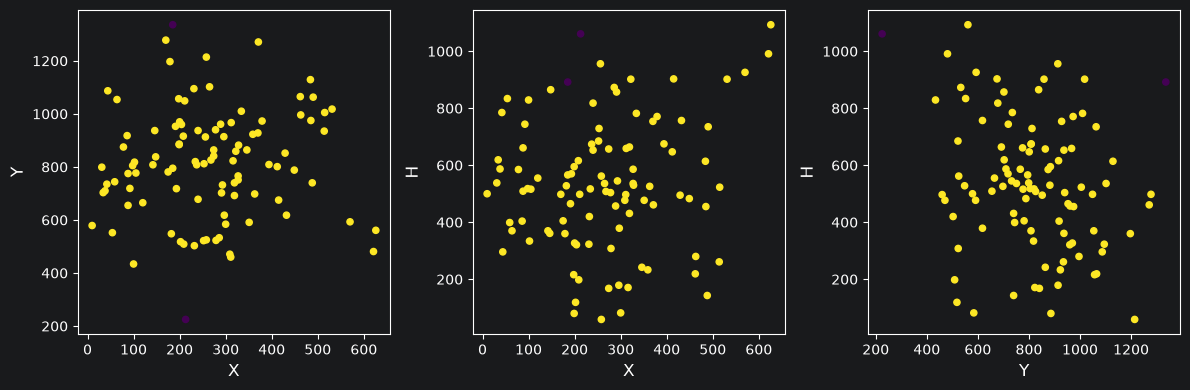

In [63]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.xlabel("X", fontsize = 12)
plt.ylabel("Y", fontsize = 12)
plt.scatter(data[:, 0], data[:, 1], c=dbscan_data, s=20)

plt.subplot(1, 3, 2)
plt.xlabel("X", fontsize = 12)
plt.ylabel("H", fontsize = 12)
plt.scatter(data[:, 0], data[:, 2], c=dbscan_data, s=20)

plt.subplot(1, 3, 3)
plt.xlabel("Y", fontsize = 12)
plt.ylabel("H", fontsize = 12)
plt.scatter(data[:, 1], data[:, 2], c=dbscan_data, s=20)

plt.tight_layout()
plt.show()

В итоге dbscan выделил 2 здания. На графиках видно что одно здание превышает расстояние 300 метров по координатам, а другое по высоте. По условию нужно 1, так что буду увеличивать параметр eps пока не останется 1 здание.

Во спрятался в здании №3 по координатам [ 185 1336  892]


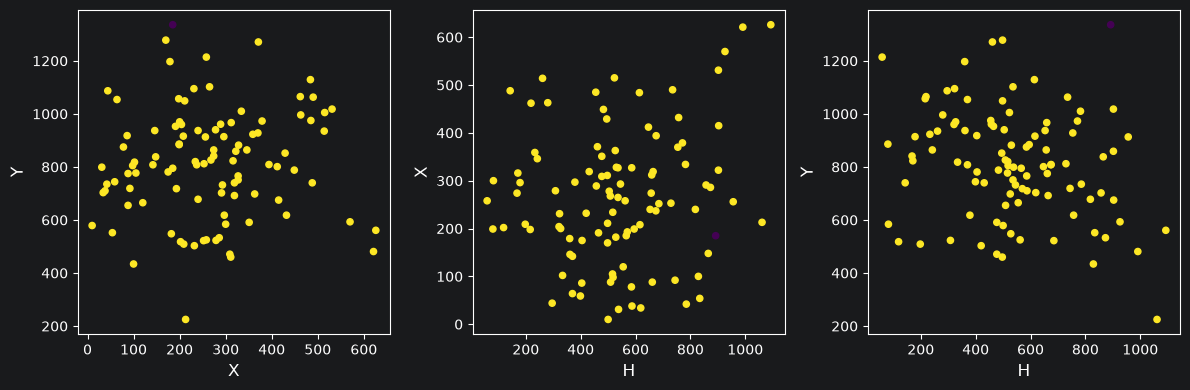

In [60]:
eps = 301
STEP = 1

while True:
    dbscan = DBSCAN(eps=eps).fit_predict(data)
    count = np.sum(dbscan == -1)
    if count == 1:
        break
    eps += STEP


for i, coordinate in enumerate(data):
    if dbscan[i] == -1:
        print(f"Во спрятался в здании №{i+1} по координатам {coordinate}")

## Графики

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.xlabel("X", fontsize = 12)
plt.ylabel("Y", fontsize = 12)
plt.scatter(data[:, 0], data[:, 1], c=dbscan, s=20)

plt.subplot(1, 3, 2)
plt.xlabel("H", fontsize = 12)
plt.ylabel("X", fontsize = 12)
plt.scatter(data[:, 2], data[:, 0], c=dbscan, s=20)

plt.subplot(1, 3, 3)
plt.xlabel("H", fontsize = 12)
plt.ylabel("Y", fontsize = 12)
plt.scatter(data[:, 2], data[:, 1], c=dbscan, s=20)

plt.tight_layout()
plt.show()